In [34]:
from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from sklearn.preprocessing import normalize
from sklearn.neighbors import NearestNeighbors

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [35]:
!pip install -q sentence-transformers python-louvain
from sentence_transformers import SentenceTransformer
import community.community_louvain as community_louvain

In [36]:
BASE_DIR = "/content/drive/MyDrive/thesis_movie_project"
PROCESSED_DIR = f"{BASE_DIR}/processed"
OUTPUT_DIR = f"{BASE_DIR}/outputs"

os.makedirs(PROCESSED_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

DATA_PATH = f"{PROCESSED_DIR}/df_semantic_analysis.csv"
df = pd.read_csv(DATA_PATH, low_memory=False)

print("Loaded:", df.shape)
display(df.head(3))

Loaded: (42709, 27)


,id,movieId,imdb_id,title,overview,keywords_clean,cast_clean,director_name,genres_clean,original_language,...,vote_average,vote_count,text_overview_only,text_semantic_enriched,text_semantic_full,overview_len,overview_word_count,budget_clean,revenue_clean,roi_clean
0,37087,105406.0,tt0042176,711 Ocean Drive,The Horatio Alger parable gets the film noir t...,gambling criminal syndicate bookie horse track...,Edmond O'Brien Joanne Dru Otto Kruger Barry Ke...,Joseph M. Newman,Drama Crime,en,...,6.1,8.0,The Horatio Alger parable gets the film noir t...,711 Ocean Drive gambling criminal syndicate bo...,711 Ocean Drive gambling criminal syndicate bo...,539,85,NaN,NaN,NaN
1,33474,71560.0,tt0042179,Abbott and Costello in the Foreign Legion,Jonesy and Lou are in Algeria looking for a wr...,foreign legion wrestler,Bud Abbott Lou Costello Patricia Medina Marc L...,Charles Lamont,Comedy,en,...,6.7,12.0,Jonesy and Lou are in Algeria looking for a wr...,Abbott and Costello in the Foreign Legion fore...,Abbott and Costello in the Foreign Legion fore...,311,51,NaN,NaN,NaN
2,705,926.0,tt0042192,All About Eve,From the moment she glimpses her idol at the s...,jealousy obsession manipulation fan engagement...,Bette Davis Anne Baxter George Sanders Celeste...,Joseph L. Mankiewicz,Drama,en,...,8.0,367.0,From the moment she glimpses her idol at the s...,All About Eve jealousy obsession manipulation ...,All About Eve jealousy obsession manipulation ...,424,71,1400000.0,63463.0,0.045331


In [37]:
# numeric safety
for col in ["runtime", "vote_count", "popularity", "release_year", "revenue"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# text safety
text_cols = ["title", "overview", "text_overview_only", "text_semantic_enriched", "text_semantic_full"]
for col in text_cols:
    if col in df.columns:
        df[col] = df[col].fillna("").astype(str).str.strip()

# helper columns
df["overview_len"] = df["overview"].str.len()
df["overview_word_count"] = df["overview"].str.split().str.len()

df["revenue_clean"] = pd.to_numeric(df["revenue"], errors="coerce")
df.loc[df["revenue_clean"] <= 0, "revenue_clean"] = np.nan

print("Cleanup complete.")

Cleanup complete.


In [38]:
text_column = "text_semantic_enriched"

df[text_column] = df[text_column].fillna("").astype(str).str.strip()

# Final safety filter
df = df[
    (df["title"].str.len() > 0) &
    (df[text_column].str.len() > 40) &
    (df["runtime"].fillna(0) >= 60) &
    (df["release_year"].notna())
].copy().reset_index(drop=True)

print("Working shape:", df.shape)
print("Using text column:", text_column)

Working shape: (42709, 27)
Using text column: text_semantic_enriched


In [39]:
model_name = "all-MiniLM-L6-v2"
model = SentenceTransformer(model_name)

print("Loaded model:", model_name)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Loaded model: all-MiniLM-L6-v2


In [40]:
sentences = df[text_column].tolist()

embeddings = model.encode(
    sentences,
    batch_size=128,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)

print("Embeddings shape:", embeddings.shape)

Batches:   0%|          | 0/334 [00:00<?, ?it/s]

Embeddings shape: (42709, 384)


In [41]:
EMB_PATH = f"{PROCESSED_DIR}/sbert_semantic_enriched_embeddings.npy"
IDX_PATH = f"{PROCESSED_DIR}/sbert_semantic_enriched_index.csv"

np.save(EMB_PATH, embeddings)
df[["id", "title", "release_year", "vote_count", "popularity", "genres_clean"]].to_csv(IDX_PATH, index=False)

print("Saved:")
print("-", EMB_PATH)
print("-", IDX_PATH)

Saved:
- /content/drive/MyDrive/thesis_movie_project/processed/sbert_semantic_enriched_embeddings.npy
- /content/drive/MyDrive/thesis_movie_project/processed/sbert_semantic_enriched_index.csv


In [42]:
K = 10

knn = NearestNeighbors(
    n_neighbors=K + 1,
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)

knn.fit(embeddings)
distances, indices = knn.kneighbors(embeddings)

print("distances shape:", distances.shape)
print("indices shape:", indices.shape)

distances shape: (42709, 11)
indices shape: (42709, 11)


In [43]:
movie_ids = df["id"].values

# directed neighbor lookup
directed_neighbors = {}
for i in range(len(movie_ids)):
    src_id = movie_ids[i]
    neigh = set()
    for j in range(1, K + 1):  # skip self
        tgt_idx = indices[i, j]
        tgt_id = movie_ids[tgt_idx]
        similarity = 1.0 - distances[i, j]
        if src_id != tgt_id and similarity > 0:
            neigh.add((tgt_id, similarity))
    directed_neighbors[src_id] = neigh

neighbor_id_lookup = {
    src: set(tgt for tgt, _ in neighs)
    for src, neighs in directed_neighbors.items()
}

edges = []
seen_pairs = set()

for i in range(len(movie_ids)):
    src_id = movie_ids[i]
    for j in range(1, K + 1):
        tgt_idx = indices[i, j]
        tgt_id = movie_ids[tgt_idx]
        similarity = 1.0 - distances[i, j]

        if src_id == tgt_id or similarity <= 0:
            continue

        pair = tuple(sorted((src_id, tgt_id)))
        if pair in seen_pairs:
            continue

        if (tgt_id in neighbor_id_lookup[src_id]) and (src_id in neighbor_id_lookup.get(tgt_id, set())):
            edges.append((src_id, tgt_id, similarity))
            seen_pairs.add(pair)

edges_df = pd.DataFrame(edges, columns=["source", "target", "weight"])

print("Mutual-KNN edges:", edges_df.shape)
display(edges_df.head())

Mutual-KNN edges: (91586, 3)


,source,target,weight
0,33474,33475,0.511367
1,33474,33476,0.444985
2,705,578118,0.587404
3,705,320703,0.532210
4,705,432887,0.515013


In [44]:
G = nx.Graph()
G.add_nodes_from(df["id"].values)

for src, tgt, w in edges:
    G.add_edge(src, tgt, weight=w)

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())
print("Density:", nx.density(G))

isolates = list(nx.isolates(G))
print("Isolated nodes:", len(isolates))

Nodes: 42709
Edges: 91586
Density: 0.00010042236625765687
Isolated nodes: 2646


In [45]:
components = list(nx.connected_components(G))
components = sorted(components, key=len, reverse=True)

largest_cc = components[0]
G_lcc = G.subgraph(largest_cc).copy()

df_lcc = df[df["id"].isin(largest_cc)].copy().reset_index(drop=True)

print("Largest connected component nodes:", G_lcc.number_of_nodes())
print("Largest connected component edges:", G_lcc.number_of_edges())
print("Share of original nodes kept:", round(G_lcc.number_of_nodes() / G.number_of_nodes() * 100, 2), "%")

Largest connected component nodes: 39345
Largest connected component edges: 90951
Share of original nodes kept: 92.12 %


In [46]:
degree_dict = dict(G_lcc.degree())
weighted_degree_dict = dict(G_lcc.degree(weight="weight"))
pagerank_dict = nx.pagerank(G_lcc, weight="weight")

metrics_df = df_lcc[[
    "id", "title", "release_year", "genres_clean",
    "vote_count", "popularity", "revenue_clean"
]].copy()

metrics_df["degree"] = metrics_df["id"].map(degree_dict)
metrics_df["weighted_degree"] = metrics_df["id"].map(weighted_degree_dict)
metrics_df["pagerank"] = metrics_df["id"].map(pagerank_dict)

display(metrics_df.head())

,id,title,release_year,genres_clean,vote_count,popularity,revenue_clean,degree,weighted_degree,pagerank
0,33474,Abbott and Costello in the Foreign Legion,1950.0,Comedy,12.0,0.992299,NaN,2,0.956351,0.000015
1,705,All About Eve,1950.0,Drama,367.0,12.063080,63463.0,4,2.137320,0.000023
2,22924,Armored Car Robbery,1950.0,Crime,12.0,2.393434,NaN,3,1.785030,0.000019
3,23325,At War with the Army,1950.0,Comedy,13.0,3.355457,NaN,9,4.466367,0.000051
4,32929,Backfire,1950.0,Mystery,4.0,4.597515,NaN,5,2.531472,0.000026


In [47]:
partition = community_louvain.best_partition(G_lcc, weight="weight", random_state=42)
metrics_df["community_id"] = metrics_df["id"].map(partition)

print("Number of communities:", metrics_df["community_id"].nunique())
display(metrics_df["community_id"].value_counts().head(15))

Number of communities: 55


,count
community_id,
54,2086
33,2050
41,1845
10,1817
29,1763
2,1755
40,1733
42,1685
19,1498


In [48]:
top_global = metrics_df.sort_values("pagerank", ascending=False).head(25)

display(
    top_global[[
        "title", "release_year", "vote_count", "popularity",
        "degree", "weighted_degree", "pagerank", "community_id"
    ]]
)

,title,release_year,vote_count,popularity,degree,weighted_degree,pagerank,community_id
30144,Incision,2020.0,29.0,3.006000,10,5.209247,0.000066,22
7292,The Nutty Professor,1996.0,717.0,9.651581,9,4.541756,0.000065,39
24170,Edge of the Knife,2018.0,9.0,1.107000,7,3.382328,0.000063,49
1488,The Reptile,1966.0,21.0,1.420766,9,4.726813,0.000061,30
854,The Flesh and the Fiends,1960.0,7.0,3.367599,5,2.364979,0.000061,31
32730,Knock Knock,2021.0,9.0,1.214000,7,3.537821,0.000061,42
28258,Sakalakalashala,2019.0,2.0,1.225000,4,1.801839,0.000060,41
23521,Affairs of State,2018.0,25.0,5.506000,10,5.129377,0.000060,6
8170,Himalaya,1999.0,18.0,1.349366,8,3.990053,0.000060,33
29109,Working Man,2019.0,6.0,2.032000,10,5.096020,0.000059,4


In [49]:
MIN_PRESENTATION_VOTES = 50
# You can also try 100 later

top_recognizable = (
    metrics_df[metrics_df["vote_count"].fillna(0) >= MIN_PRESENTATION_VOTES]
    .sort_values("pagerank", ascending=False)
    .head(25)
)

display(
    top_recognizable[[
        "title", "release_year", "vote_count", "popularity",
        "degree", "weighted_degree", "pagerank", "community_id"
    ]]
)

,title,release_year,vote_count,popularity,degree,weighted_degree,pagerank,community_id
7292,The Nutty Professor,1996.0,717.0,9.651581,9,4.541756,0.000065,39
25257,Ramen Shop,2018.0,95.0,7.123000,9,4.962173,0.000059,39
28350,Skin,2019.0,354.0,13.729000,10,5.322913,0.000059,2
33591,The Dig,2021.0,1069.0,14.929000,8,3.792326,0.000058,16
11802,The Night Listener,2006.0,58.0,11.478867,10,5.281652,0.000057,4
26771,Burn,2019.0,243.0,22.119000,7,3.713126,0.000057,2
7364,Austin Powers: International Man of Mystery,1997.0,1033.0,11.749159,7,3.756291,0.000056,28
10252,Dhoom,2004.0,53.0,3.106495,10,5.821653,0.000056,33
10905,Kirikou and the Wild Beasts,2005.0,65.0,4.040988,6,2.887239,0.000056,22
25024,"New Year, New You",2018.0,61.0,2.947000,10,5.807639,0.000055,27


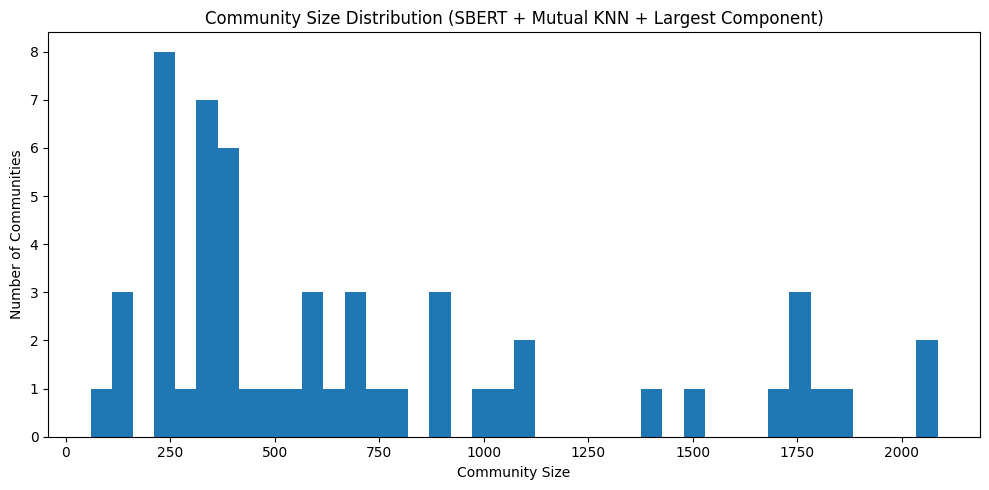

,community_id,size
0,54,2086
1,33,2050
2,41,1845
3,10,1817
4,29,1763
5,2,1755
6,40,1733
7,42,1685
8,19,1498
9,26,1399


In [50]:
community_sizes = metrics_df["community_id"].value_counts().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
plt.hist(community_sizes.values, bins=40)
plt.title("Community Size Distribution (SBERT + Mutual KNN + Largest Component)")
plt.xlabel("Community Size")
plt.ylabel("Number of Communities")
plt.tight_layout()
plt.show()

display(community_sizes.head(20).rename_axis("community_id").reset_index(name="size"))

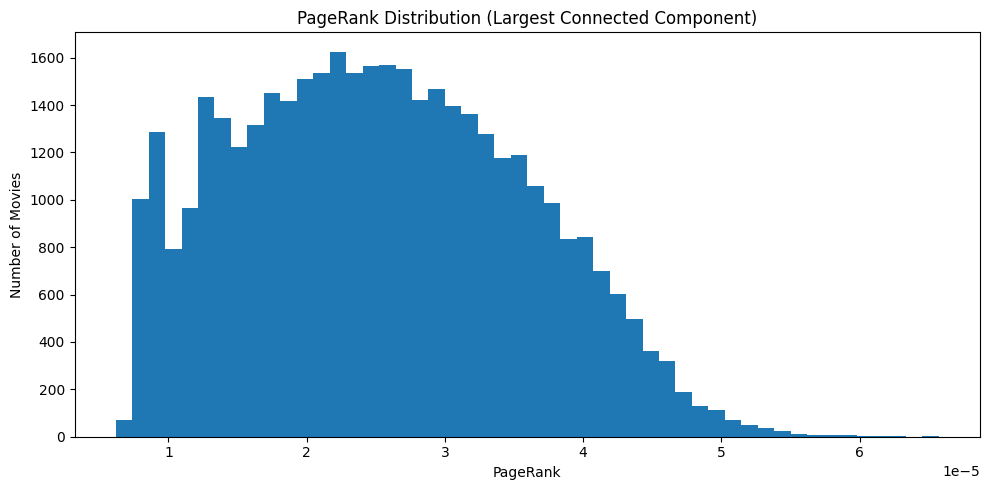

In [51]:
plt.figure(figsize=(10, 5))
plt.hist(metrics_df["pagerank"], bins=50)
plt.title("PageRank Distribution (Largest Connected Component)")
plt.xlabel("PageRank")
plt.ylabel("Number of Movies")
plt.tight_layout()
plt.show()

In [52]:
major_communities = community_sizes.head(10).index.tolist()

rows = []
for c in major_communities:
    subset = metrics_df[metrics_df["community_id"] == c].copy()
    subset = subset.sort_values("pagerank", ascending=False).head(5)
    subset["community_size"] = len(metrics_df[metrics_df["community_id"] == c])
    rows.append(subset)

top_by_community = pd.concat(rows, ignore_index=True)

display(
    top_by_community[[
        "community_id", "community_size", "title", "release_year",
        "vote_count", "popularity", "pagerank"
    ]]
)

,community_id,community_size,title,release_year,vote_count,popularity,pagerank
0,54,2086,The Disappeared,2008.0,10.0,0.901538,0.000058
1,54,2086,In My Room,2018.0,30.0,3.276000,0.000054
2,54,2086,Happy End,1967.0,11.0,1.663297,0.000053
3,54,2086,My Mom Is a Character 2,2016.0,100.0,4.117801,0.000053
4,54,2086,Death to 2020,2020.0,660.0,11.144000,0.000052
5,33,2050,Himalaya,1999.0,18.0,1.349366,0.000060
6,33,2050,Soni,2019.0,33.0,2.829000,0.000058
7,33,2050,Dhoom,2004.0,53.0,3.106495,0.000056
8,33,2050,Padayappa,1999.0,13.0,1.135828,0.000055
9,33,2050,Damnation,1988.0,16.0,1.489647,0.000055


In [53]:
metrics_path = f"{PROCESSED_DIR}/sbert_interpretive_network_metrics.csv"
edges_path = f"{PROCESSED_DIR}/sbert_interpretive_network_edges.csv"
lcc_path = f"{PROCESSED_DIR}/df_semantic_analysis_lcc.csv"
recognizable_path = f"{PROCESSED_DIR}/sbert_interpretive_top_recognizable.csv"

metrics_df.to_csv(metrics_path, index=False)
edges_df.to_csv(edges_path, index=False)
df_lcc.to_csv(lcc_path, index=False)
top_recognizable.to_csv(recognizable_path, index=False)

print("Saved:")
print("-", metrics_path)
print("-", edges_path)
print("-", lcc_path)
print("-", recognizable_path)

Saved:
- /content/drive/MyDrive/thesis_movie_project/processed/sbert_interpretive_network_metrics.csv
- /content/drive/MyDrive/thesis_movie_project/processed/sbert_interpretive_network_edges.csv
- /content/drive/MyDrive/thesis_movie_project/processed/df_semantic_analysis_lcc.csv
- /content/drive/MyDrive/thesis_movie_project/processed/sbert_interpretive_top_recognizable.csv


In [54]:
print("FINAL NETWORK STATUS")
print("--------------------")
print("Original filtered analysis set:", df.shape)
print("Graph nodes:", G.number_of_nodes())
print("Graph edges:", G.number_of_edges())
print("Isolates:", len(isolates))
print("Largest CC nodes:", G_lcc.number_of_nodes())
print("Largest CC edges:", G_lcc.number_of_edges())
print("Communities in largest CC:", metrics_df["community_id"].nunique())

print("\nFor thesis interpretation, use:")
print("- sbert_interpretive_network_metrics.csv")
print("- sbert_interpretive_top_recognizable.csv")
print("- top central movies within major communities")

FINAL NETWORK STATUS
--------------------
Original filtered analysis set: (42709, 27)
Graph nodes: 42709
Graph edges: 91586
Isolates: 2646
Largest CC nodes: 39345
Largest CC edges: 90951
Communities in largest CC: 55

For thesis interpretation, use:
- sbert_interpretive_network_metrics.csv
- sbert_interpretive_top_recognizable.csv
- top central movies within major communities


**05_tfidf_interpretive_networkt**


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize
from sklearn.neighbors import NearestNeighbors

import networkx as nx

Mounted at /content/drive


In [18]:
BASE_DIR = "/content/drive/MyDrive/thesis_movie_project"
PROCESSED_DIR = f"{BASE_DIR}/processed"
OUTPUT_DIR = f"{BASE_DIR}/outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

df = pd.read_csv(f"{PROCESSED_DIR}/df_semantic_analysis.csv", low_memory=False)

print("Original semantic core shape:", df.shape)
display(df.head(3))

Original semantic core shape: (42709, 27)


,id,movieId,imdb_id,title,overview,keywords_clean,cast_clean,director_name,genres_clean,original_language,...,vote_average,vote_count,text_overview_only,text_semantic_enriched,text_semantic_full,overview_len,overview_word_count,budget_clean,revenue_clean,roi_clean
0,37087,105406.0,tt0042176,711 Ocean Drive,The Horatio Alger parable gets the film noir t...,gambling criminal syndicate bookie horse track...,Edmond O'Brien Joanne Dru Otto Kruger Barry Ke...,Joseph M. Newman,Drama Crime,en,...,6.1,8.0,The Horatio Alger parable gets the film noir t...,711 Ocean Drive gambling criminal syndicate bo...,711 Ocean Drive gambling criminal syndicate bo...,539,85,NaN,NaN,NaN
1,33474,71560.0,tt0042179,Abbott and Costello in the Foreign Legion,Jonesy and Lou are in Algeria looking for a wr...,foreign legion wrestler,Bud Abbott Lou Costello Patricia Medina Marc L...,Charles Lamont,Comedy,en,...,6.7,12.0,Jonesy and Lou are in Algeria looking for a wr...,Abbott and Costello in the Foreign Legion fore...,Abbott and Costello in the Foreign Legion fore...,311,51,NaN,NaN,NaN
2,705,926.0,tt0042192,All About Eve,From the moment she glimpses her idol at the s...,jealousy obsession manipulation fan engagement...,Bette Davis Anne Baxter George Sanders Celeste...,Joseph L. Mankiewicz,Drama,en,...,8.0,367.0,From the moment she glimpses her idol at the s...,All About Eve jealousy obsession manipulation ...,All About Eve jealousy obsession manipulation ...,424,71,1400000.0,63463.0,0.045331


In [19]:
# numeric safety
for col in ["runtime", "vote_count", "popularity", "release_year", "revenue"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# text safety
for col in ["title", "overview", "text_overview_only", "text_semantic_enriched", "text_semantic_full"]:
    df[col] = df[col].fillna("").astype(str).str.strip()

df["overview_len"] = df["overview"].str.len()
df["overview_word_count"] = df["overview"].str.split().str.len()

# revenue cleaning
df["revenue_clean"] = pd.to_numeric(df["revenue"], errors="coerce")
df.loc[df["revenue_clean"] <= 0, "revenue_clean"] = np.nan

In [20]:
# Interpretation-oriented filter:
# keep movie-like and somewhat visible titles

df_interpretive = df[
    (df["overview_len"] > 30) &
    (df["runtime"].fillna(0) >= 60) &
    (df["release_year"].notna()) &
    (
        (df["vote_count"].fillna(0) >= 20) |
        (df["popularity"].fillna(0) >= 5.0) |
        (df["revenue_clean"].notna())
    )
].copy().reset_index(drop=True)

print("Interpretive subset shape:", df_interpretive.shape)

print("\nCoverage diagnostics:")
print("vote_count >= 10:", (df_interpretive["vote_count"].fillna(0) >= 10).mean() * 100)
print("popularity >= 1:", (df_interpretive["popularity"].fillna(0) >= 1).mean() * 100)
print("revenue > 0:", df_interpretive["revenue_clean"].notna().mean() * 100)

Interpretive subset shape: (23380, 27)

Coverage diagnostics:
vote_count >= 10: 89.06757912745937
popularity >= 1: 96.1847733105218
revenue > 0: 36.796407185628745


In [21]:
text_column = "text_overview_only"
# text_column = "text_semantic_enriched"

df_interpretive[text_column] = df_interpretive[text_column].fillna("").astype(str).str.strip()
df_interpretive = df_interpretive[df_interpretive[text_column].str.len() > 30].copy().reset_index(drop=True)

print("Working shape after final text filter:", df_interpretive.shape)
print("Using text column:", text_column)

Working shape after final text filter: (23380, 27)
Using text column: text_overview_only


In [22]:
tfidf = TfidfVectorizer(
    max_features=30000,
    min_df=5,
    max_df=0.8,
    stop_words="english",
    ngram_range=(1, 2)
)

X_tfidf = tfidf.fit_transform(df_interpretive[text_column])

print("TF-IDF shape:", X_tfidf.shape)

TF-IDF shape: (23380, 21911)


In [23]:
svd = TruncatedSVD(n_components=256, random_state=42)
X_svd = svd.fit_transform(X_tfidf)
X_emb = normalize(X_svd)

print("Reduced embedding shape:", X_emb.shape)
print("Explained variance ratio sum:", svd.explained_variance_ratio_.sum())

Reduced embedding shape: (23380, 256)
Explained variance ratio sum: 0.14982832222919745


In [24]:
K = 10

knn = NearestNeighbors(
    n_neighbors=K + 1,
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)

knn.fit(X_emb)
distances, indices = knn.kneighbors(X_emb)

print("distances shape:", distances.shape)
print("indices shape:", indices.shape)

distances shape: (23380, 11)
indices shape: (23380, 11)


In [25]:
movie_ids = df_interpretive["id"].values

# first build directed neighbor relations
directed_neighbors = {}

for i in range(len(movie_ids)):
    src_id = movie_ids[i]
    neigh = set()
    for j in range(1, K + 1):  # skip self
        tgt_idx = indices[i, j]
        tgt_id = movie_ids[tgt_idx]
        similarity = 1.0 - distances[i, j]
        if src_id != tgt_id and similarity > 0:
            neigh.add((tgt_id, similarity))
    directed_neighbors[src_id] = neigh

# convert to lookup set of ids only
neighbor_id_lookup = {
    src: set(tgt for tgt, _ in neighs)
    for src, neighs in directed_neighbors.items()
}

# keep only mutual neighbors
edges = []
seen_pairs = set()

for i in range(len(movie_ids)):
    src_id = movie_ids[i]
    for j in range(1, K + 1):
        tgt_idx = indices[i, j]
        tgt_id = movie_ids[tgt_idx]
        similarity = 1.0 - distances[i, j]

        if src_id == tgt_id or similarity <= 0:
            continue

        pair = tuple(sorted((src_id, tgt_id)))
        if pair in seen_pairs:
            continue

        # mutual KNN condition
        if (tgt_id in neighbor_id_lookup[src_id]) and (src_id in neighbor_id_lookup.get(tgt_id, set())):
            edges.append((src_id, tgt_id, similarity))
            seen_pairs.add(pair)

edges_df = pd.DataFrame(edges, columns=["source", "target", "weight"])

print("Mutual-KNN edge list shape:", edges_df.shape)
edges_df.head()

Mutual-KNN edge list shape: (45747, 3)


,source,target,weight
0,25209,54087,0.533785
1,25209,84329,0.448979
2,25209,739993,0.414977
3,24481,771257,0.572184
4,24481,37931,0.565224


In [26]:
G = nx.Graph()
G.add_nodes_from(df_interpretive["id"].values)

for src, tgt, w in edges:
    G.add_edge(src, tgt, weight=w)

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())
print("Density:", nx.density(G))

isolates = list(nx.isolates(G))
print("Isolated nodes:", len(isolates))

Nodes: 23380
Edges: 45747
Density: 0.0001673871739207512
Isolated nodes: 1812


In [27]:
# Optional: restrict interpretive analysis to connected nodes only
connected_ids = set(G.nodes()) - set(nx.isolates(G))

df_graph = df_interpretive[df_interpretive["id"].isin(connected_ids)].copy().reset_index(drop=True)
G_sub = G.subgraph(connected_ids).copy()

print("Connected analysis subset shape:", df_graph.shape)
print("Connected graph nodes:", G_sub.number_of_nodes())
print("Connected graph edges:", G_sub.number_of_edges())

Connected analysis subset shape: (21568, 27)
Connected graph nodes: 21568
Connected graph edges: 45747


In [28]:
degree_dict = dict(G_sub.degree())
weighted_degree_dict = dict(G_sub.degree(weight="weight"))
pagerank_dict = nx.pagerank(G_sub, weight="weight")

metrics_df = df_graph[[
    "id", "title", "release_year", "genres_clean",
    "vote_count", "popularity", "revenue_clean"
]].copy()

metrics_df["degree"] = metrics_df["id"].map(degree_dict)
metrics_df["weighted_degree"] = metrics_df["id"].map(weighted_degree_dict)
metrics_df["pagerank"] = metrics_df["id"].map(pagerank_dict)

metrics_df.head()

,id,title,release_year,genres_clean,vote_count,popularity,revenue_clean,degree,weighted_degree,pagerank
0,25209,Annie Get Your Gun,1950.0,Action Comedy Music Romance Western,22.0,2.090588,8000000.0,3,1.397741,0.000034
1,24481,Born Yesterday,1950.0,Comedy Romance Drama,35.0,6.085287,NaN,10,5.321627,0.000092
2,43385,Born to Be Bad,1950.0,Drama,6.0,9.743518,NaN,5,2.705512,0.000052
3,37292,Broken Arrow,1950.0,Western,33.0,8.836250,NaN,4,1.826500,0.000044
4,33839,Cheaper by the Dozen,1950.0,Comedy Family,25.0,2.084567,NaN,5,2.560061,0.000046


In [29]:
partition = community_louvain.best_partition(G_sub, weight="weight", random_state=42)
metrics_df["community_id"] = metrics_df["id"].map(partition)

print("Number of communities:", metrics_df["community_id"].nunique())
display(metrics_df["community_id"].value_counts().head(15))

Number of communities: 291


,count
community_id,
11,753
1,724
18,582
6,562
13,527
46,525
26,508
72,508
14,488


In [30]:
top_pagerank = metrics_df.sort_values("pagerank", ascending=False).head(25)

display(
    top_pagerank[[
        "title", "release_year", "vote_count", "popularity",
        "degree", "weighted_degree", "pagerank", "community_id"
    ]]
)

,title,release_year,vote_count,popularity,degree,weighted_degree,pagerank,community_id
14480,Selfie from Hell,2018.0,52.0,2.874000,7,2.824232,0.000137,4
5931,Tae Guk Gi: The Brotherhood of War,2004.0,134.0,9.140411,5,3.266954,0.000125,95
20678,Female College Student's Massage,2023.0,0.0,11.522000,10,4.814237,0.000119,11
6610,Rob-B-Hood,2006.0,107.0,12.183711,9,4.691682,0.000115,1
8307,Father of Invention,2010.0,48.0,3.688516,10,5.107610,0.000112,67
6966,Moliere,2007.0,46.0,4.821828,10,5.303365,0.000112,69
18315,Juan Luis Guerra 4.40: Entre Mar y Palmeras,2021.0,41.0,3.226000,9,4.529213,0.000111,45
11427,The Revenant,2015.0,6558.0,23.501228,10,5.210749,0.000111,21
17638,The Way Back,2020.0,1010.0,9.852000,8,4.659274,0.000110,25
2847,The Rookie,1990.0,134.0,8.110591,10,5.210871,0.000110,37


In [31]:
top100 = metrics_df.sort_values("pagerank", ascending=False).head(100)

print("Median vote_count in full interpretive graph:", metrics_df["vote_count"].median())
print("Median vote_count in top 100 PageRank:", top100["vote_count"].median())

print("\n% of top 100 with vote_count <= 10:")
print((top100["vote_count"].fillna(0) <= 10).mean() * 100)

print("\n% of top 100 with revenue available:")
print(top100["revenue_clean"].notna().mean() * 100)

Median vote_count in full interpretive graph: 52.0
Median vote_count in top 100 PageRank: 51.5

% of top 100 with vote_count <= 10:
15.0

% of top 100 with revenue available:
37.0


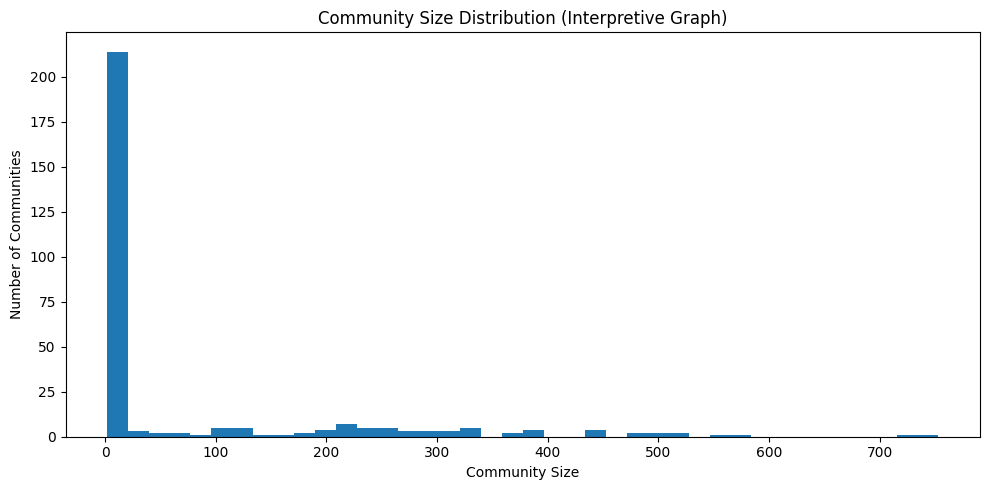

,community_id,size
0,11,753
1,1,724
2,18,582
3,6,562
4,13,527
5,46,525
6,26,508
7,72,508
8,14,488
9,79,483


In [32]:
community_sizes = metrics_df["community_id"].value_counts().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
plt.hist(community_sizes.values, bins=40)
plt.title("Community Size Distribution (Interpretive Graph)")
plt.xlabel("Community Size")
plt.ylabel("Number of Communities")
plt.tight_layout()
plt.show()

display(community_sizes.head(20).rename_axis("community_id").reset_index(name="size"))

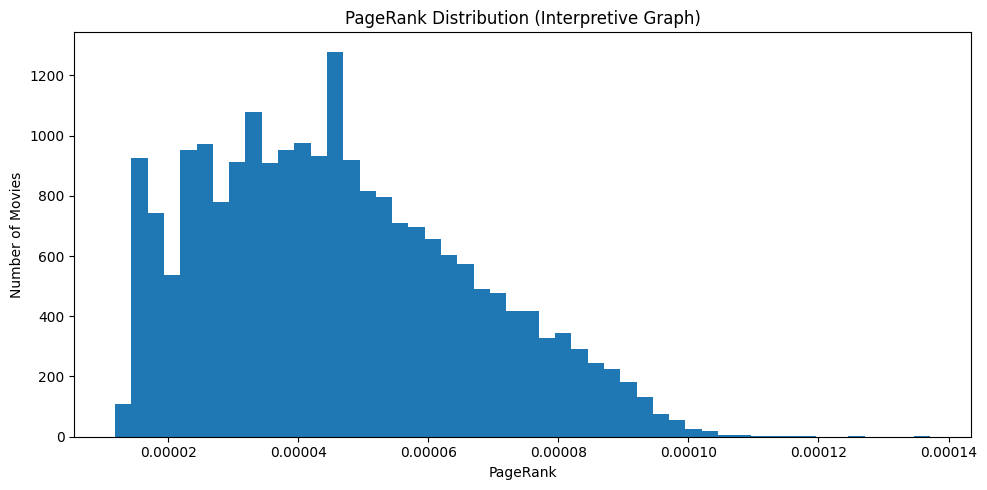

In [33]:
plt.figure(figsize=(10, 5))
plt.hist(metrics_df["pagerank"], bins=50)
plt.title("PageRank Distribution (Interpretive Graph)")
plt.xlabel("PageRank")
plt.ylabel("Number of Movies")
plt.tight_layout()
plt.show()

In [ ]:
SAVE_DIR = PROCESSED_DIR

df_interpretive.to_csv(f"{SAVE_DIR}/df_semantic_interpretive.csv", index=False)
metrics_df.to_csv(f"{SAVE_DIR}/tfidf_interpretive_network_metrics.csv", index=False)
edges_df.to_csv(f"{SAVE_DIR}/tfidf_interpretive_network_edges.csv", index=False)

print("Saved:")
print("- df_semantic_interpretive.csv")
print("- tfidf_interpretive_network_metrics.csv")
print("- tfidf_interpretive_network_edges.csv")

Saved:
- df_semantic_interpretive.csv
- tfidf_interpretive_network_metrics.csv
- tfidf_interpretive_network_edges.csv
